# Supplementary Figure S10e. Spatial organization of genes implicated through *trans*-ePrograms

Left: *cis*-neuronal genes (neuron-only *cis*-eGenes) at loci whose glial recipient signal is a *trans*-eProgram (glial-only genes among the top 10% of each program ranked by |correlation|), with Deep (L4-L6) vs Outer (L1-L3) layer DE; per gene, logFC and P are first collapsed within sample (median) and then summarised across samples (median logFC, median P; P floored at the smallest positive P), and genes with minimum sample FDR < 0.05 are shown, coloured by direction (76 Deep, 7 Outer); the six most significant Deep genes are labelled. Right: glial *trans*-eProgram genes (top 10% per program, glial-only; 2,623 genes with a mapped symbol and at least one up-regulated FDR < 0.05 layer test) comparing median -log10 P of the white-matter (WM) one-vs-rest test with the weaker of the Deep and Outer one-vs-rest tests ("cortical layers"); only up-regulated (logFC > 0, FDR < 0.05) sample-level results enter each median, and a gene with none in a region gets 0. The dashed line is y = x; the six genes furthest above it are labelled. The right panel was rebuilt with the Figure 4g scatter code applied to the *trans*-eProgram gene set, because the cell that produced the original panel is no longer in the source notebook (the top labelled genes MBP, PLP1, TF, CNP, CLDN11, SCD and their values match the saved figure). Descriptive; no statistical test.

Input: `data/Figure_S10e_eprogram_spatial.rds`

In [1]:
library(ggplot2)
library(ggrepel)
library(patchwork)
res <- readRDS("data/Figure_S10e_eprogram_spatial.rds")
table(res$cis_neuron$de_layer)
nrow(res$trans_glia)


 Deep Outer 
   76     7 

[1] 2623

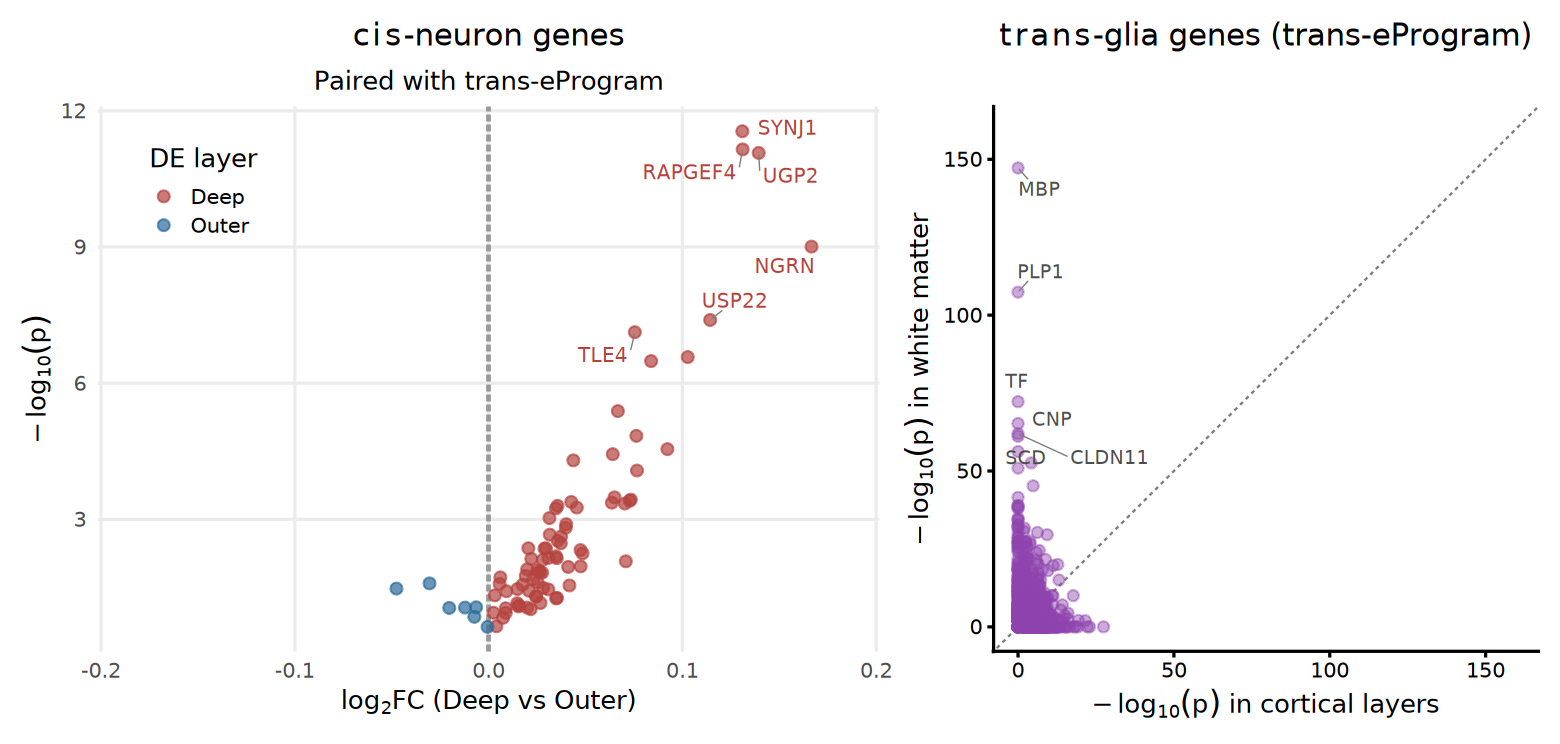

In [2]:
cis_df <- res$cis_neuron
deep <- cis_df[cis_df$de_layer == "Deep", ]
top_cis <- head(deep[order(-deep$med_neglog10p), ], 6)
xlim_val <- max(abs(cis_df$med_logFC)) * 1.1
p_cis <- ggplot(cis_df, aes(x = med_logFC, y = med_neglog10p, colour = de_layer)) +
  geom_vline(xintercept = 0, linetype = "longdash", colour = "grey60", linewidth = 1) +
  geom_point(size = 2.6, alpha = 0.7) +
  geom_text_repel(data = top_cis, aes(label = symbol), colour = "#B5423E", size = 4.2,
                  box.padding = 0.55, segment.colour = "grey50", segment.size = 0.3,
                  max.overlaps = Inf, seed = 2026) +
  scale_colour_manual(values = c("Deep" = "#B5423E", "Outer" = "#2B6A99"), name = "DE layer") +
  scale_x_continuous(limits = c(-xlim_val, xlim_val)) +
  labs(title = expression(italic(cis) * "-neuron genes"), subtitle = "Paired with trans-eProgram",
       x = expression(log[2] * "FC (Deep vs Outer)"), y = expression(-log[10](p))) +
  theme_minimal(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5), plot.subtitle = element_text(hjust = 0.5),
        legend.position = "inside", legend.position.inside = c(0.05, 0.95),
        legend.justification = c(0, 1), panel.grid.minor = element_blank())

tg <- res$trans_glia
top_tg <- head(tg[order(-(tg$neglog10p_wm - tg$neglog10p_cortical)), ], 6)
lim <- max(c(tg$neglog10p_cortical, tg$neglog10p_wm)) * 1.08
p_tg <- ggplot(tg, aes(x = neglog10p_cortical, y = neglog10p_wm)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50", linewidth = 0.5) +
  geom_point(alpha = 0.45, size = 2.4, colour = "#8E44AD") +
  geom_text_repel(data = top_tg, aes(label = gene), size = 4, colour = "grey30",
                  box.padding = 0.5, segment.colour = "grey50", segment.size = 0.3,
                  max.overlaps = Inf, seed = 1) +
  scale_x_continuous(limits = c(0, lim)) + scale_y_continuous(limits = c(0, lim)) +
  coord_fixed() +
  labs(title = expression(italic(trans) * "-glia genes (trans-eProgram)"),
       x = expression(-log[10](p) ~ "in cortical layers"),
       y = expression(-log[10](p) ~ "in white matter")) +
  theme_classic(base_size = 15) + theme(plot.title = element_text(hjust = 0.5))

options(repr.plot.width = 13, repr.plot.height = 6.2)
p_cis + p_tg